# Etape 1 : Analyse des données

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Chargement direct et robuste du dataset synthétique
candidates = [
    Path('../credit_risk_dataset.csv'),    
]
csv_path = next((p for p in candidates if p.exists()), Path('credit_risk_dataset.csv'))
df = pd.read_csv(csv_path)

print(f'Données chargées depuis : {csv_path.resolve()}')
print('Dimensions du dataset :', df.shape)
print('Distribution de la cible (decision_octroi) :')
print(df['decision_octroi'].value_counts(normalize=True).round(3))
df.head()


Données chargées depuis : C:\GIT\formation-AI\2026-ATLAS-Brief-M0B1\credit_risk_dataset.csv
Dimensions du dataset : (1200, 17)
Distribution de la cible (decision_octroi) :
decision_octroi
0    0.623
1    0.377
Name: proportion, dtype: float64


,id_dossier,montant_demande,duree_mois,revenu_mensuel,taux_endettement,age,sexe,statut_marital,nationalite,situation_logement,anciennete_emploi_mois,type_contrat,epargne_globale,nb_credits_actifs,incident_precedent,score_credit,decision_octroi
0,DOS-10000,16100.0,48,3800.0,0.088,27,M,celibataire,FR,proprietaire,31,CDI,1820.0,0,retard_leger,621.0,1
1,DOS-10001,11100.0,12,3030.0,0.305,20,F,marie,FR,proprietaire,281,CDI,5930.0,0,aucun,693.8,1
2,DOS-10002,16100.0,12,3980.0,0.337,19,M,divorce,FR,locataire,38,CDI,980.0,2,aucun,677.8,1
3,DOS-10003,19900.0,72,5030.0,0.055,24,F,divorce,HORS_UE,proprietaire,48,CDD,20490.0,0,retard_leger,634.4,1
4,DOS-10004,15400.0,24,2920.0,0.220,32,F,divorce,FR,locataire,45,CDI,3570.0,1,retard_leger,634.2,1


Diagnostic qualité

In [69]:
diagnostic = pd.DataFrame({
    "Type": df.dtypes.astype(str),
    "Valeurs manquantes": df.isna().sum(),
    "Manquants (%)": df.isna().mean().mul(100).round(2),
    "Valeurs distinctes": df.nunique(),
})

display(diagnostic)

,Type,Valeurs manquantes,Manquants (%),Valeurs distinctes
id_dossier,str,0,0.0,1200
montant_demande,float64,0,0.0,317
duree_mois,int64,0,0.0,7
revenu_mensuel,float64,0,0.0,407
taux_endettement,float64,0,0.0,393
age,int64,0,0.0,56
sexe,str,0,0.0,2
statut_marital,str,0,0.0,4
nationalite,str,0,0.0,3
situation_logement,str,0,0.0,3


Distribution de décision octroi

In [70]:
distribution = pd.DataFrame({
    "Effectif": df["decision_octroi"].value_counts(),
    "Pourcentage": df["decision_octroi"]
        .value_counts(normalize=True).mul(100).round(1),
})

display(distribution)

,Effectif,Pourcentage
decision_octroi,,
0,748,62.3
1,452,37.7


Le dataset contient 1200 lignes et 17 colonnes. Aucune colonne ne présentent de valeurs manquantes. Les refus représentent  62,3 % des dossiers, contre 37,7% d’accords. La classe minoritaire est donc les accords.

# Étape 2 : Feature Engineering Raisonné

**Reste à vivre estimé**

Formule : revenu_mensuel - (montant_demande / duree_mois)

La mensualité est estimée en répartissant uniformément le capital sur la durée du prêt. Elle ne comprend ni les intérêts ni l’assurance. Le reste à vivre est exprimé en euros par mois : ce n’est pas un ratio.

Cette estimation ne déduit ni les autres crédits, ni le loyer, ni les dépenses courantes. Elle constitue un indicateur simplifié, pas le véritable budget disponible du client.

**Ratio épargne / emprunt**

Formule : epargne_globale / montant_demande

Ce ratio, sans unité, mesure la couverture du montant demandé par l’épargne. Une valeur de 0,25 signifie une couverture de 25 %. Une valeur supérieure à 1 est possible et signifie que l’épargne dépasse le montant demandé.

**Gestion des cas limites**

Les dénominateurs nuls, négatifs ou manquants produisent une valeur manquante plutôt qu’une division invalide. Ces valeurs seront imputées par la médiane apprise uniquement sur les données d’entraînement de chaque pli. Aucune ligne n’est supprimée.

L’intérêt prédictif de ces variables reste une hypothèse métier : leur gain doit être vérifié par une comparaison avec et sans elles sur les mêmes plis, sans utiliser le test final.

In [71]:
# Conserver les données originales
df_features = df.copy()

# Éviter les divisions par zéro ou par une valeur négative
duree_valide = df_features["duree_mois"].where(
    df_features["duree_mois"] > 0
)
montant_valide = df_features["montant_demande"].where(
    df_features["montant_demande"] > 0
)

mensualite_estimee = df_features["montant_demande"] / duree_valide

df_features["reste_a_vivre_estime"] = (
    df_features["revenu_mensuel"] - mensualite_estimee
)

df_features["ratio_epargne_emprunt"] = (
    df_features["epargne_globale"] / montant_valide
)

df_features[
    ["reste_a_vivre_estime", "ratio_epargne_emprunt"]
].head()

,reste_a_vivre_estime,ratio_epargne_emprunt
0,3464.583333,0.113043
1,2105.000000,0.534234
2,2638.333333,0.060870
3,4753.611111,1.029648
4,2278.333333,0.231818


# Étape 3 : Construction du Pipeline Scikit-Learn Étanche

## 1. Intégrer les variables métier au pipeline

In [72]:
from sklearn.preprocessing import FunctionTransformer

def ajouter_variables_metier(X):
    X = X.copy()

    duree = X["duree_mois"].where(X["duree_mois"] > 0)
    montant = X["montant_demande"].where(X["montant_demande"] > 0)

    X["reste_a_vivre_estime"] = (
        X["revenu_mensuel"] - X["montant_demande"] / duree
    )
    X["ratio_epargne_emprunt"] = X["epargne_globale"] / montant

    return X

## 2. Définition des deux branches de prétraitement

In [73]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

branche_numerique = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler()),
])

branche_categorielle = Pipeline([
    ("imputation", SimpleImputer(
        strategy="constant",
        fill_value="INCONNU",
    )),
    ("encodage", OneHotEncoder(handle_unknown="ignore")),
])

pretraitement = ColumnTransformer([
    (
        "numerique",
        branche_numerique,
        make_column_selector(dtype_include="number"),
    ),
    (
        "categorielle",
        branche_categorielle,
        make_column_selector(dtype_exclude="number"),
    ),
])

## 3. Assemblage d'un pipeline

In [74]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

pipeline_regression = Pipeline([
    ("variables_metier", FunctionTransformer(ajouter_variables_metier)),
    ("pretraitement", clone(pretraitement)),
    ("modele", RandomForestRegressor(random_state=42)),
])

pipeline_classification = Pipeline([
    ("variables_metier", FunctionTransformer(ajouter_variables_metier)),
    ("pretraitement", clone(pretraitement)),
    ("modele", RandomForestClassifier(random_state=42)),
])

On clone les pipeline en modifiant le modèle

In [75]:
from sklearn.ensemble import (
    GradientBoostingRegressor,
    GradientBoostingClassifier,
)

pipeline_gb_regression = clone(pipeline_regression).set_params(
    modele=GradientBoostingRegressor(random_state=42)
)

pipeline_gb_classification = clone(pipeline_classification).set_params(
    modele=GradientBoostingClassifier(random_state=42)
)

# Étape 4 : Validation Croisée K-Fold Stratifiée

 1. On écarte les données score_credit et decision_octroi qui sont les résultats attendus ainsi que l'id technique

In [76]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["id_dossier", "score_credit", "decision_octroi"])
y_reg = df["score_credit"]
y_clf = df["decision_octroi"]

(
    X_train, X_test,
    y_reg_train, y_reg_test,
    y_clf_train, y_clf_test,
) = train_test_split(
    X,
    y_reg,
    y_clf,
    test_size=0.20,
    stratify=y_clf,
    random_state=42,
)

2. Préparer les cinq plis sur le train

In [77]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

plis = list(cv.split(X_train, y_clf_train))

3. Evaluation des pipelines

Pipeline RandomForest

In [78]:
from sklearn.metrics import make_scorer, recall_score, f1_score
from sklearn.model_selection import cross_validate

scores_reg = cross_validate(
    pipeline_regression,
    X_train,
    y_reg_train,
    cv=plis,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
    error_score="raise",
)

scores_clf = cross_validate(
    pipeline_classification,
    X_train,
    y_clf_train,
    cv=plis,
    scoring={
        "roc_auc": "roc_auc",
        "rappel_refus": make_scorer(
            recall_score, pos_label=0, zero_division=0
        ),
        "f1_refus": make_scorer(
            f1_score, pos_label=0, zero_division=0
        ),
    },
    error_score="raise",
)


Détails pour chaque pli

In [79]:
resultats_plis_rf = pd.DataFrame({
    "R²": scores_reg["test_r2"],
    "MAE": -scores_reg["test_mae"],
    "RMSE": -scores_reg["test_rmse"],
    "ROC-AUC": scores_clf["test_roc_auc"],
    "Rappel refus": scores_clf["test_rappel_refus"],
    "F1 refus": scores_clf["test_f1_refus"],
}, index=range(1, 6))

resultats_plis_rf.index.name = "Pli"

display(resultats_plis_rf.round(3))

,R²,MAE,RMSE,ROC-AUC,Rappel refus,F1 refus
Pli,,,,,,
1,0.665,30.265,37.188,0.858,0.866,0.837
2,0.682,29.696,37.656,0.903,0.924,0.863
3,0.585,31.803,39.575,0.855,0.817,0.824
4,0.606,34.328,41.555,0.858,0.792,0.812
5,0.538,31.899,39.111,0.868,0.892,0.839


Gradient Boosting

In [80]:
scores_gb_reg = cross_validate(
    pipeline_gb_regression,
    X_train,
    y_reg_train,
    cv=plis,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
    error_score="raise",
)

scores_gb_clf = cross_validate(
    pipeline_gb_classification,
    X_train,
    y_clf_train,
    cv=plis,
    scoring={
        "roc_auc": "roc_auc",
        "rappel_refus": make_scorer(
            recall_score, pos_label=0, zero_division=0
        ),
        "f1_refus": make_scorer(
            f1_score, pos_label=0, zero_division=0
        ),
    },
    error_score="raise",
)

Détails pour chaque pli

In [81]:
resultats_plis_gb = pd.DataFrame({
    "R²": scores_gb_reg["test_r2"],
    "MAE": -scores_gb_reg["test_mae"],
    "RMSE": -scores_gb_reg["test_rmse"],
    "ROC-AUC": scores_gb_clf["test_roc_auc"],
    "Rappel refus": scores_gb_clf["test_rappel_refus"],
    "F1 refus": scores_gb_clf["test_f1_refus"],
}, index=range(1, 6))

resultats_plis_gb.index.name = "Pli"

display(resultats_plis_gb.round(3))

,R²,MAE,RMSE,ROC-AUC,Rappel refus,F1 refus
Pli,,,,,,
1,0.684,29.094,36.123,0.865,0.840,0.833
2,0.652,31.340,39.360,0.896,0.941,0.885
3,0.598,30.976,38.960,0.876,0.833,0.844
4,0.606,33.638,41.555,0.863,0.825,0.822
5,0.543,31.270,38.882,0.859,0.883,0.841


Tableaux comparatifs

In [82]:
def moyenne_ecart_type(valeurs):
    return f"{valeurs.mean():.3f} +/- {valeurs.std(ddof=0):.3f}"

In [83]:
comparaison_reg = pd.DataFrame({
    "Random Forest": {
        "R²": moyenne_ecart_type(scores_reg["test_r2"]),
        "MAE": moyenne_ecart_type(-scores_reg["test_mae"]),
        "RMSE": moyenne_ecart_type(-scores_reg["test_rmse"]),
    },
    "Gradient Boosting": {
        "R²": moyenne_ecart_type(scores_gb_reg["test_r2"]),
        "MAE": moyenne_ecart_type(-scores_gb_reg["test_mae"]),
        "RMSE": moyenne_ecart_type(-scores_gb_reg["test_rmse"]),
    },
}).T

display(comparaison_reg)

,R²,MAE,RMSE
Random Forest,0.615 +/- 0.053,31.598 +/- 1.611,39.017 +/- 1.547
Gradient Boosting,0.617 +/- 0.048,31.264 +/- 1.444,38.976 +/- 1.729


In [84]:
comparaison_clf = pd.DataFrame({
    "Random Forest": {
        "ROC-AUC": moyenne_ecart_type(scores_clf["test_roc_auc"]),
        "Rappel refus": moyenne_ecart_type(scores_clf["test_rappel_refus"]),
        "F1 refus": moyenne_ecart_type(scores_clf["test_f1_refus"]),
    },
    "Gradient Boosting": {
        "ROC-AUC": moyenne_ecart_type(scores_gb_clf["test_roc_auc"]),
        "Rappel refus": moyenne_ecart_type(scores_gb_clf["test_rappel_refus"]),
        "F1 refus": moyenne_ecart_type(scores_gb_clf["test_f1_refus"]),
    },
}).T

display(comparaison_clf)

,ROC-AUC,Rappel refus,F1 refus
Random Forest,0.868 +/- 0.018,0.858 +/- 0.048,0.835 +/- 0.017
Gradient Boosting,0.872 +/- 0.013,0.865 +/- 0.043,0.845 +/- 0.022


### Interprétation des performances en régression

Les deux modèles sont évalués sur les mêmes cinq plis de validation, à partir du train uniquement. Le test final n’a pas été utilisé. Les résultats correspondent aux paramètres par défaut.

**Random Forest**

- R² = 0,615 +/- 0,053 : le modèle explique en moyenne 61,5 % de la variabilité des scores sur les plis de validation.
- MAE = 31,598 +/- 1,611 : les prédictions s’écartent du score réel d’environ 31,6 points en moyenne.
- RMSE = 39,017 +/- 1,547 : cette erreur, plus sensible aux écarts importants, montre que certaines prédictions sont moins précises.

**Gradient Boosting**

- R² = 0,617 +/- 0,048 : le modèle explique en moyenne 61,7 % de la variabilité des scores, soit un résultat très proche de Random Forest.
- MAE = 31,264 +/- 1,444 : l’erreur absolue moyenne est d’environ 31,3 points, soit une réduction de seulement 0,334 point par rapport à Random Forest.
- RMSE = 38,976 +/- 1,729 : le résultat est presque identique à celui de Random Forest. La dispersion entre les plis est légèrement plus élevée pour cette métrique.

**Comparaison et limites**

Gradient Boosting obtient des moyennes légèrement meilleures sur les trois métriques. Son R² et sa MAE sont également un peu plus réguliers entre les plis, mais pas sa RMSE.

Les écarts-types décrivent la variation des scores entre les plis ; ils ne constituent pas des intervalles de confiance. Les faibles différences observées ne permettent pas, à elles seules, d’affirmer une supériorité nette.

### Interprétation des performances en classification

Les résultats suivants utilisent les mêmes cinq plis de validation. La classe 0 représente un refus et la classe 1 un accord. Le rappel et le F1 sont calculés explicitement pour les refus avec pos_label=0, même si les accords sont la classe minoritaire.

**Random Forest**

- ROC-AUC = 0,868 +/- 0,018 : le modèle distingue relativement bien les accords des refus. Cette métrique mesure la qualité du classement des dossiers, pas le taux de bonnes prédictions.
- Rappel des refus = 0,858 +/- 0,048 : en moyenne par pli, 85,8 % des refus historiques sont détectés et 14,2 % sont prédits comme accords.
- F1 des refus = 0,835 +/- 0,017 : ce score résume le compromis entre la précision des refus prédits et la détection des refus historiques.

**Gradient Boosting**

- ROC-AUC = 0,872 +/- 0,013 : le classement est légèrement meilleur en moyenne que celui de Random Forest, avec un gain de 0,004.
- Rappel des refus = 0,865 +/- 0,043 : en moyenne par pli, 86,5 % des refus historiques sont détectés et 13,5 % sont prédits comme accords. Le gain de rappel est de 0,7 point de pourcentage.
- F1 des refus = 0,845 +/- 0,022 : le compromis précision-rappel est légèrement meilleur en moyenne, mais plus variable entre les plis que pour Random Forest.

**Comparaison et limites**

Gradient Boosting présente un léger avantage moyen sur les trois métriques. Sa ROC-AUC et son rappel des refus sont plus réguliers entre les plis, mais pas son F1. Ces écarts modestes ne démontrent pas à eux seuls une supériorité nette.

Les refus historiques prédits comme accords et les accords prédits comme refus n’ont pas nécessairement le même coût métier. Une matrice de confusion permettra de détailler ces erreurs lors de l’évaluation finale. Les décisions historiques ne mesurent pas directement les défauts de remboursement réels.

**Conclusion**

Les deux familles présentent des performances comparables et sont conservées pour l’optimisation avec Optuna. Le choix final reposera sur les résultats de validation croisée après optimisation, avant toute évaluation sur le test réservé.

## Étape 5 : Optimisation Bayésienne avec Optuna

### Compréhension / Notes

#### Objectif de l’optimisation

Les modèles ont d’abord été comparés avec leurs paramètres par défaut. Optuna va rechercher des hyperparamètres plus performants pour Random Forest et Gradient Boosting, sans modifier le protocole de validation. Une amélioration n’est pas garantie.

Les hyperparamètres sont des réglages choisis avant l’entraînement :

| Hyperparamètre | Rôle |
| --- | --- |
| `n_estimators` | Nombre d’arbres du modèle. |
| `max_depth` | Profondeur maximale des arbres, qui limite leur complexité. |
| `min_samples_leaf` | Nombre minimal de dossiers dans une feuille. |
| `learning_rate` | Poids des corrections successives, pour Gradient Boosting uniquement. |

Le but est de trouver un compromis entre un modèle trop simple, qui manque des relations importantes, et un modèle trop complexe, qui risque de surapprendre le train.

#### Fonctionnement d’Optuna

- **Trial (essai)** : une combinaison d’hyperparamètres évaluée.
- **Objective (fonction objectif)** : fonction qui construit et évalue le pipeline avec ces réglages, puis renvoie un score numérique à Optuna.
- **Study (étude)** : ensemble des essais consacrés à un objectif.
- **Sampler TPE** : méthode qui commence par explorer, puis utilise les résultats précédents pour orienter les essais vers les zones prometteuses. Elle ne teste pas toutes les combinaisons et ne garantit pas de trouver l’optimum absolu.

Déroulement d’un essai : proposition de réglages → copie non entraînée du pipeline → validation sur les cinq plis → calcul du score moyen → retour du score à Optuna.

#### Métriques à optimiser

| Défi | Objectif principal | Direction |
| --- | --- | --- |
| Régression | R² moyen sur les cinq plis | Maximiser |
| Classification | ROC-AUC moyenne sur les cinq plis | Maximiser |

Chaque étude optimise une seule métrique principale. La MAE, la RMSE, le rappel et le F1 des refus restent nécessaires pour analyser les compromis. Le rappel et le F1 des refus sont calculés avec `pos_label=0` ; la ROC-AUC utilise les scores ou probabilités de la classe accord (1).

#### Protocole anti-fuite de données

1. Créer une copie indépendante et non entraînée du pipeline à chaque essai, puis lui appliquer les hyperparamètres proposés.
2. Évaluer ce pipeline avec `cross_validate`, uniquement sur `X_train` et la cible d’entraînement correspondante.
3. Réutiliser les mêmes cinq découpages `plis` que pour la comparaison initiale. Ils sont stratifiés sur `y_clf_train` et réutilisés pour la régression, dont la cible est continue.
4. Conserver les transformations métier et tous les prétraitements dans le pipeline. Les médianes, paramètres de standardisation et catégories sont appris uniquement sur les quatre plis d’entraînement de chaque tour.
5. Renvoyer à Optuna la moyenne des cinq scores de validation. Ne pas utiliser `X_test`, `y_reg_test` ou `y_clf_test` dans les objectifs, ni pour choisir les réglages.

Les noms `test_*` renvoyés par `cross_validate` désignent les validations internes aux plis, pas le test final réservé. Une erreur d’entraînement doit rester visible, par exemple avec `error_score='raise'`.

#### Organisation prévue des expériences

Quatre études distinctes permettront de comparer clairement les familles pour chaque défi :

1. Random Forest — régression.
2. Gradient Boosting — régression.
3. Random Forest — classification.
4. Gradient Boosting — classification.

Le budget initial prévu est de **20 essais par étude**, soit **4 × 20 × 5 = 400 entraînements de pipelines**, hors comparaisons initiales et évaluations complémentaires. Ce budget est un choix de départ, pas une garantie de convergence.

Les espaces de recherche devront être explicites et adaptés à chaque famille : bornes pour le nombre d’arbres, la profondeur et la taille minimale des feuilles ; recherche du taux d’apprentissage uniquement pour le boosting. Fixer la graine du sampler TPE, des modèles et des plis à 42 pour faciliter la reproduction. Éviter le parallélisme imbriqué excessif.

#### Résultats à conserver et interpréter

- Nombre d’essais réalisés, espaces explorés et meilleurs hyperparamètres de chaque étude.
- Meilleur score CV et métriques du pipeline retenu présentées sous forme **moyenne +/- écart-type** sur les mêmes cinq plis.
- Tableau comparatif avant/après optimisation pour les deux familles et les deux défis.
- Courbes de convergence montrant l’évolution du meilleur score trouvé au fil des essais. Un plateau indique que les derniers essais n’ont pas amélioré le résultat, pas que l’optimum absolu est atteint.

La sélection du meilleur essai parmi de nombreux essais peut rendre son score CV optimiste. L’écart-type entre plis ne constitue pas un intervalle de confiance et ne supprime pas ce biais de sélection.

Après comparaison sur la validation croisée, figer le choix des deux pipelines et leurs réglages. Les entraîner ensuite sur tout le train, puis les évaluer sur le test final réservé. Ne pas relancer une boucle de tuning guidée par les résultats du test.

**Prochaine étape pratique :** construire d’abord la fonction objectif de Random Forest en régression, vérifier son fonctionnement, puis décliner la méthode pour les trois autres études. Ces notes décrivent la méthode prévue ; elles ne constituent pas encore des résultats d’optimisation.

### 1. Optimisation Random Forest — Régression

**Fonction Objectif**

- trial.suggest_* propose les valeurs dans les bornes choisies.
- modele__max_depth signifie : modifier max_depth dans l’étape modele du pipeline.
- La fonction retourne un seul nombre : le R² moyen des cinq plis.
- test_score désigne ici les scores de validation interne, pas le test final.

In [85]:
import optuna

from sklearn.base import clone
from sklearn.model_selection import cross_validate


def objectif_rf_regression(trial):
    # Optuna propose une combinaison de réglages
    parametres = {
        "modele__n_estimators": trial.suggest_int(
            "n_estimators", 100, 300, step=50
        ),
        "modele__max_depth": trial.suggest_int(
            "max_depth", 3, 20
        ),
        "modele__min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),
    }

    pipeline_essai = clone(pipeline_regression).set_params(**parametres)

    scores = cross_validate(
        pipeline_essai,
        X_train,
        y_reg_train,
        cv=plis,
        scoring="r2",
        error_score="raise",
        n_jobs=1,
    )

    trial.set_user_attr(
        "r2_ecart_type",
        float(scores["test_score"].std(ddof=0)),
    )

    return float(scores["test_score"].mean())

Création et Lancement de l'étude

In [86]:
etude_rf_regression = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

etude_rf_regression.optimize(
    objectif_rf_regression,
    n_trials=20,
)

print("Meilleurs hyperparamètres :", etude_rf_regression.best_params)
print(
    f"Meilleur R² CV : {etude_rf_regression.best_value:.3f}"
    f" +/- "
    f"{etude_rf_regression.best_trial.user_attrs['r2_ecart_type']:.3f}"
)

[I 2026-11-18 10:21:55,964] A new study created in memory with name: no-name-325bb479-0169-43db-9190-255627b0f4b4
[I 2026-11-18 10:22:00,262] Trial 0 finished with value: 0.6208694215708819 and parameters: {'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 8}. Best is trial 0 with value: 0.6208694215708819.
[I 2026-11-18 10:22:05,141] Trial 1 finished with value: 0.6172380175875337 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.6208694215708819.
[I 2026-11-18 10:22:08,195] Trial 2 finished with value: 0.6217611762820882 and parameters: {'n_estimators': 100, 'max_depth': 18, 'min_samples_leaf': 7}. Best is trial 2 with value: 0.6217611762820882.
[I 2026-11-18 10:22:12,873] Trial 3 finished with value: 0.5333473005438109 and parameters: {'n_estimators': 250, 'max_depth': 3, 'min_samples_leaf': 10}. Best is trial 2 with value: 0.6217611762820882.
[I 2026-11-18 10:22:19,996] Trial 4 finished with value: 0.6205064507332687

Meilleurs hyperparamètres : {'n_estimators': 250, 'max_depth': 12, 'min_samples_leaf': 6}
Meilleur R² CV : 0.624 +/- 0.047


Cela représente 20 essais × 5 plis = 100 entraînements.

Chaque réexécution de .optimize() ajoute des essais à l’étude existante ; réexécuter aussi create_study() recrée une étude vide.

**Construction du pipeline optimisé et comparaison**

On réévalue les réglages retenus pour obtenir également MAE et RMSE :

In [87]:
pipeline_rf_regression_opt = clone(pipeline_regression).set_params(
    **{
        f"modele__{nom}": valeur
        for nom, valeur in etude_rf_regression.best_params.items()
    }
)

scores_rf_reg_opt = cross_validate(
    pipeline_rf_regression_opt,
    X_train,
    y_reg_train,
    cv=plis,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
    error_score="raise",
    n_jobs=1,
)

comparaison_rf_optuna = pd.DataFrame({
    "Avant optimisation": {
        "R²": moyenne_ecart_type(scores_reg["test_r2"]),
        "MAE": moyenne_ecart_type(-scores_reg["test_mae"]),
        "RMSE": moyenne_ecart_type(-scores_reg["test_rmse"]),
    },
    "Après optimisation": {
        "R²": moyenne_ecart_type(scores_rf_reg_opt["test_r2"]),
        "MAE": moyenne_ecart_type(-scores_rf_reg_opt["test_mae"]),
        "RMSE": moyenne_ecart_type(-scores_rf_reg_opt["test_rmse"]),
    },
}).T

display(comparaison_rf_optuna)

,R²,MAE,RMSE
Avant optimisation,0.615 +/- 0.053,31.598 +/- 1.611,39.017 +/- 1.547
Après optimisation,0.624 +/- 0.047,31.071 +/- 1.534,38.579 +/- 1.490


**La convergence**

C:\Users\A127375\AppData\Local\Temp\ipykernel_31480\3956452038.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(etude_rf_regression)


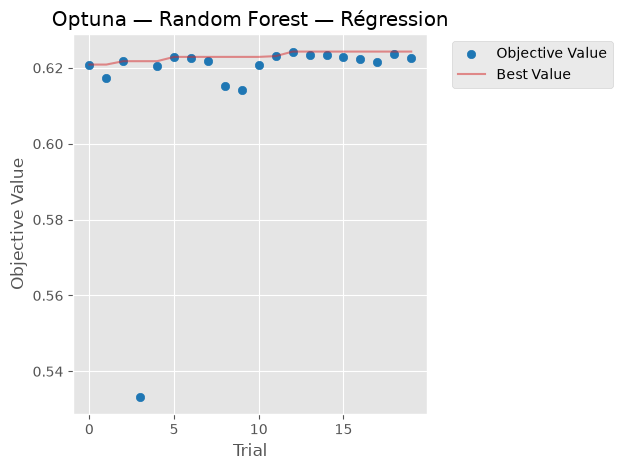

In [88]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import plot_optimization_history

plot_optimization_history(etude_rf_regression)
plt.title("Optuna — Random Forest — Régression")
plt.tight_layout()
plt.show()

### 2. Optimisation Gradient Boosting — Régression

Le protocole reste identique : mêmes données d’entraînement, mêmes cinq plis et maximisation du R² moyen. Les résultats Random Forest restent conservés dans leurs variables.

L’espace de recherche comprend `n_estimators` de 50 à 300 par pas de 50, `max_depth` de 1 à 4, `min_samples_leaf` de 1 à 10 et `learning_rate` de 0,01 à 0,2 sur une échelle logarithmique. Un faible taux d’apprentissage peut nécessiter davantage d’arbres. Ces bornes constituent un choix initial, pas une garantie d’optimalité.

**Fonction objectif** : cloner le pipeline Gradient Boosting, appliquer les réglages proposés et renvoyer le R² moyen sur les cinq plis, sans utiliser le test final.

In [89]:
def objectif_gb_regression(trial):
    parametres = {
        "modele__n_estimators": trial.suggest_int(
            "n_estimators", 50, 300, step=50
        ),
        "modele__max_depth": trial.suggest_int(
            "max_depth", 1, 4
        ),
        "modele__min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),
        "modele__learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
    }

    pipeline_essai = clone(pipeline_gb_regression).set_params(**parametres)

    scores = cross_validate(
        pipeline_essai,
        X_train,
        y_reg_train,
        cv=plis,
        scoring="r2",
        error_score="raise",
        n_jobs=1,
    )

    trial.set_user_attr(
        "r2_ecart_type",
        float(scores["test_score"].std(ddof=0)),
    )

    return float(scores["test_score"].mean())

**Création et lancement de l’étude**

Le budget de 20 essais correspond à 100 entraînements sur cinq plis. Exécuter de nouveau toute cette cellule recrée une étude vide ; appeler seulement `.optimize()` sur l’étude existante ajoute des essais.

In [90]:
etude_gb_regression = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

etude_gb_regression.optimize(
    objectif_gb_regression,
    n_trials=20,
)

print("Meilleurs hyperparamètres :", etude_gb_regression.best_params)
print(
    f"Meilleur R² CV : {etude_gb_regression.best_value:.3f}"
    f" +/- "
    f"{etude_gb_regression.best_trial.user_attrs['r2_ecart_type']:.3f}"
)

[I 2026-11-18 10:23:57,841] A new study created in memory with name: no-name-1b2ba440-ed63-47a3-ac75-4fa77a1ab20f
[I 2026-11-18 10:24:01,857] Trial 0 finished with value: 0.6037678865637848 and parameters: {'n_estimators': 150, 'max_depth': 4, 'min_samples_leaf': 8, 'learning_rate': 0.060099747183803134}. Best is trial 0 with value: 0.6037678865637848.
[I 2026-11-18 10:24:02,486] Trial 1 finished with value: 0.6138134372336435 and parameters: {'n_estimators': 50, 'max_depth': 1, 'min_samples_leaf': 1, 'learning_rate': 0.13394334706750485}. Best is trial 1 with value: 0.6138134372336435.
[I 2026-11-18 10:24:06,903] Trial 2 finished with value: 0.5677239754306553 and parameters: {'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 1, 'learning_rate': 0.18276027831785724}. Best is trial 1 with value: 0.6138134372336435.
[I 2026-11-18 10:24:09,903] Trial 3 finished with value: 0.5488503202092714 and parameters: {'n_estimators': 250, 'max_depth': 1, 'min_samples_leaf': 2, 'learning_rat

Meilleurs hyperparamètres : {'n_estimators': 200, 'max_depth': 1, 'min_samples_leaf': 9, 'learning_rate': 0.09589983842092037}
Meilleur R² CV : 0.653 +/- 0.044


**Construction du pipeline optimisé et comparaison**

Réévaluer les réglages retenus sur les mêmes plis permet de présenter R², MAE et RMSE avant/après optimisation. Le pipeline d’origine reste inchangé. Le pipeline optimisé reste lui aussi non entraîné : `cross_validate` entraîne des copies.

Le meilleur score CV après sélection parmi plusieurs essais peut être optimiste. L’amélioration doit être analysée avec sa dispersion, sans consulter le test final.

In [91]:
pipeline_gb_regression_opt = clone(pipeline_gb_regression).set_params(
    **{
        f"modele__{nom}": valeur
        for nom, valeur in etude_gb_regression.best_params.items()
    }
)

scores_gb_reg_opt = cross_validate(
    pipeline_gb_regression_opt,
    X_train,
    y_reg_train,
    cv=plis,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
    },
    error_score="raise",
    n_jobs=1,
)

comparaison_gb_optuna = pd.DataFrame({
    "Avant optimisation": {
        "R²": moyenne_ecart_type(scores_gb_reg["test_r2"]),
        "MAE": moyenne_ecart_type(-scores_gb_reg["test_mae"]),
        "RMSE": moyenne_ecart_type(-scores_gb_reg["test_rmse"]),
    },
    "Après optimisation": {
        "R²": moyenne_ecart_type(scores_gb_reg_opt["test_r2"]),
        "MAE": moyenne_ecart_type(-scores_gb_reg_opt["test_mae"]),
        "RMSE": moyenne_ecart_type(-scores_gb_reg_opt["test_rmse"]),
    },
}).T

display(comparaison_gb_optuna)

,R²,MAE,RMSE
Avant optimisation,0.617 +/- 0.048,31.264 +/- 1.444,38.976 +/- 1.729
Après optimisation,0.653 +/- 0.044,29.881 +/- 1.543,37.110 +/- 1.897


**Courbe de convergence**

Les points représentent le R² moyen de chaque essai ; la ligne suit le meilleur score trouvé jusqu’ici. Un plateau n’est pas une preuve d’optimalité. Ce graphique relit les essais terminés sans relancer d’entraînement.

C:\Users\A127375\AppData\Local\Temp\ipykernel_31480\2275080636.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(etude_gb_regression)


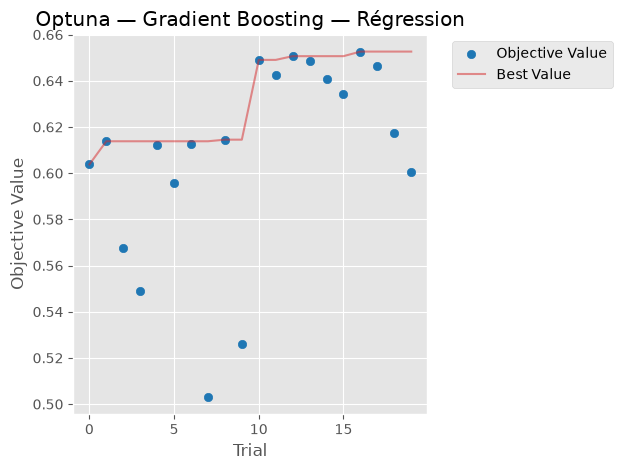

In [92]:
plot_optimization_history(etude_gb_regression)
plt.title("Optuna — Gradient Boosting — Régression")
plt.tight_layout()
plt.show()

### 3. Optimisation Random Forest — Classification

On maximise la **ROC-AUC moyenne**, évaluée sur `X_train`, `y_clf_train` et les mêmes cinq découpages `plis`. La ROC-AUC utilise les probabilités d’accord (classe 1), pas les classes prédites.

Le rappel et le F1 des refus restent des métriques complémentaires calculées avec `pos_label=0`, même si les accords sont minoritaires. Le seuil de décision standard du modèle n’est pas ajusté ici. Les données de test final ne sont jamais utilisées dans cette recherche.

L’espace de recherche reprend celui de Random Forest en régression : 100 à 300 arbres par pas de 50, profondeur de 3 à 20 et minimum de 1 à 10 dossiers par feuille. Les pipelines et les résultats de régression sont conservés.

In [93]:
import optuna
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score


def objectif_rf_classification(trial):
    parametres = {
        "modele__n_estimators": trial.suggest_int(
            "n_estimators", 100, 300, step=50
        ),
        "modele__max_depth": trial.suggest_int(
            "max_depth", 3, 20
        ),
        "modele__min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),
    }

    pipeline_essai = clone(pipeline_classification).set_params(**parametres)

    scores = cross_validate(
        pipeline_essai,
        X_train,
        y_clf_train,
        cv=plis,
        scoring="roc_auc",
        error_score="raise",
        n_jobs=1,
    )

    trial.set_user_attr(
        "roc_auc_ecart_type",
        float(scores["test_score"].std(ddof=0)),
    )

    return float(scores["test_score"].mean())

**Création et lancement de l’étude**

20 essais × 5 plis = 100 entraînements. Réexécuter la cellule entière recrée une étude vide ; appeler seulement `.optimize()` ajoute des essais à l’étude existante.

In [94]:
etude_rf_classification = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

etude_rf_classification.optimize(
    objectif_rf_classification,
    n_trials=20,
)

print("Meilleurs hyperparamètres :", etude_rf_classification.best_params)
print(
    f"Meilleure ROC-AUC CV : {etude_rf_classification.best_value:.3f}"
    f" +/- "
    f"{etude_rf_classification.best_trial.user_attrs['roc_auc_ecart_type']:.3f}"
)

[I 2026-11-18 10:24:44,228] A new study created in memory with name: no-name-321800ce-fd69-4af7-b42a-09d54f4dfd47
[I 2026-11-18 10:24:48,336] Trial 0 finished with value: 0.8709879652013012 and parameters: {'n_estimators': 150, 'max_depth': 20, 'min_samples_leaf': 8}. Best is trial 0 with value: 0.8709879652013012.
[I 2026-11-18 10:24:51,500] Trial 1 finished with value: 0.8676467630431167 and parameters: {'n_estimators': 200, 'max_depth': 5, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.8709879652013012.
[I 2026-11-18 10:24:53,311] Trial 2 finished with value: 0.8742679887784643 and parameters: {'n_estimators': 100, 'max_depth': 18, 'min_samples_leaf': 7}. Best is trial 2 with value: 0.8742679887784643.
[I 2026-11-18 10:24:56,719] Trial 3 finished with value: 0.8568278323505962 and parameters: {'n_estimators': 250, 'max_depth': 3, 'min_samples_leaf': 10}. Best is trial 2 with value: 0.8742679887784643.
[I 2026-11-18 10:25:01,222] Trial 4 finished with value: 0.8723300568324742

Meilleurs hyperparamètres : {'n_estimators': 300, 'max_depth': 16, 'min_samples_leaf': 4}
Meilleure ROC-AUC CV : 0.878 +/- 0.017


**Construction du pipeline optimisé et comparaison**

Les meilleurs réglages sont réévalués avec ROC-AUC, rappel et F1 des refus sur les mêmes plis. Une meilleure ROC-AUC n’implique pas nécessairement un meilleur rappel au seuil standard : les deux aspects doivent être commentés.

In [95]:
pipeline_rf_classification_opt = clone(pipeline_classification).set_params(
    **{
        f"modele__{nom}": valeur
        for nom, valeur in etude_rf_classification.best_params.items()
    }
)

scores_rf_clf_opt = cross_validate(
    pipeline_rf_classification_opt,
    X_train,
    y_clf_train,
    cv=plis,
    scoring={
        "roc_auc": "roc_auc",
        "rappel_refus": make_scorer(recall_score, pos_label=0, zero_division=0),
        "f1_refus": make_scorer(f1_score, pos_label=0, zero_division=0),
    },
    error_score="raise",
    n_jobs=1,
)

comparaison_rf_classification_optuna = pd.DataFrame({
    "Avant optimisation": {
        "ROC-AUC": moyenne_ecart_type(scores_clf["test_roc_auc"]),
        "Rappel refus": moyenne_ecart_type(scores_clf["test_rappel_refus"]),
        "F1 refus": moyenne_ecart_type(scores_clf["test_f1_refus"]),
    },
    "Après optimisation": {
        "ROC-AUC": moyenne_ecart_type(scores_rf_clf_opt["test_roc_auc"]),
        "Rappel refus": moyenne_ecart_type(scores_rf_clf_opt["test_rappel_refus"]),
        "F1 refus": moyenne_ecart_type(scores_rf_clf_opt["test_f1_refus"]),
    },
}).T

display(comparaison_rf_classification_optuna)

,ROC-AUC,Rappel refus,F1 refus
Avant optimisation,0.868 +/- 0.018,0.858 +/- 0.048,0.835 +/- 0.017
Après optimisation,0.878 +/- 0.017,0.868 +/- 0.037,0.841 +/- 0.017


**Courbe de convergence**

Les points représentent la ROC-AUC moyenne de chaque essai et la ligne le meilleur résultat atteint jusqu’ici. Ce graphique n’affiche pas le rappel ou le F1 et ne relance aucun entraînement.

C:\Users\A127375\AppData\Local\Temp\ipykernel_31480\3489690335.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(etude_rf_classification)


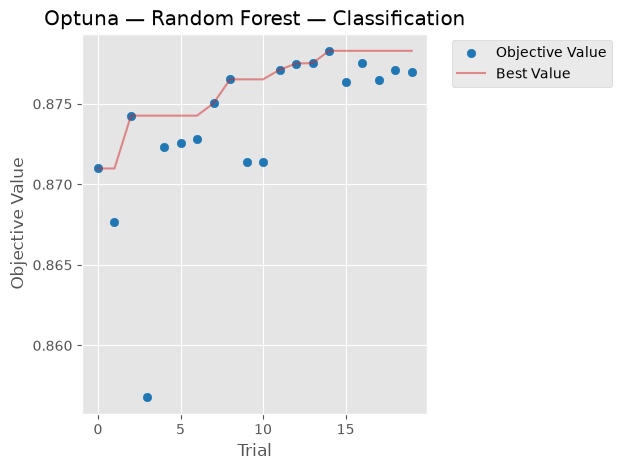

In [96]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import plot_optimization_history

plot_optimization_history(etude_rf_classification)
plt.title("Optuna — Random Forest — Classification")
plt.tight_layout()
plt.show()

### 4. Optimisation Gradient Boosting — Classification

Même objectif de ROC-AUC moyenne et mêmes cinq plis. L’espace de recherche reprend celui du boosting en régression : 50 à 300 arbres par pas de 50, profondeur de 1 à 4, minimum de 1 à 10 dossiers par feuille et taux d’apprentissage de 0,01 à 0,2 sur une échelle logarithmique.

Le taux d’apprentissage et le nombre d’arbres interagissent. Les bornes et le budget de 20 essais sont un point de départ, pas une garantie de convergence.

In [97]:
def objectif_gb_classification(trial):
    parametres = {
        "modele__n_estimators": trial.suggest_int(
            "n_estimators", 50, 300, step=50
        ),
        "modele__max_depth": trial.suggest_int(
            "max_depth", 1, 4
        ),
        "modele__min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 1, 10
        ),
        "modele__learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
    }

    pipeline_essai = clone(pipeline_gb_classification).set_params(**parametres)

    scores = cross_validate(
        pipeline_essai,
        X_train,
        y_clf_train,
        cv=plis,
        scoring="roc_auc",
        error_score="raise",
        n_jobs=1,
    )

    trial.set_user_attr(
        "roc_auc_ecart_type",
        float(scores["test_score"].std(ddof=0)),
    )

    return float(scores["test_score"].mean())

**Création et lancement de l’étude**

L’étude est indépendante de Random Forest : sa graine est également fixée à 42 et son budget initial est de 20 essais.

In [98]:
etude_gb_classification = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)

etude_gb_classification.optimize(
    objectif_gb_classification,
    n_trials=20,
)

print("Meilleurs hyperparamètres :", etude_gb_classification.best_params)
print(
    f"Meilleure ROC-AUC CV : {etude_gb_classification.best_value:.3f}"
    f" +/- "
    f"{etude_gb_classification.best_trial.user_attrs['roc_auc_ecart_type']:.3f}"
)

[I 2026-11-18 10:26:01,621] A new study created in memory with name: no-name-3818b0f1-65c4-4ffe-9ab7-7acc99ea27cb
[I 2026-11-18 10:26:06,152] Trial 0 finished with value: 0.8747166956584765 and parameters: {'n_estimators': 150, 'max_depth': 4, 'min_samples_leaf': 8, 'learning_rate': 0.060099747183803134}. Best is trial 0 with value: 0.8747166956584765.
[I 2026-11-18 10:26:06,888] Trial 1 finished with value: 0.877580855972526 and parameters: {'n_estimators': 50, 'max_depth': 1, 'min_samples_leaf': 1, 'learning_rate': 0.13394334706750485}. Best is trial 1 with value: 0.877580855972526.
[I 2026-11-18 10:26:14,876] Trial 2 finished with value: 0.8546473977718941 and parameters: {'n_estimators': 200, 'max_depth': 3, 'min_samples_leaf': 1, 'learning_rate': 0.18276027831785724}. Best is trial 1 with value: 0.877580855972526.
[I 2026-11-18 10:26:17,740] Trial 3 finished with value: 0.8694661883018048 and parameters: {'n_estimators': 250, 'max_depth': 1, 'min_samples_leaf': 2, 'learning_rate':

Meilleurs hyperparamètres : {'n_estimators': 50, 'max_depth': 3, 'min_samples_leaf': 1, 'learning_rate': 0.07570025262227631}
Meilleure ROC-AUC CV : 0.885 +/- 0.016


**Construction du pipeline optimisé et comparaison**

Comme pour Random Forest, on conserve le pipeline d’origine et on réévalue un clone configuré avec les meilleurs hyperparamètres. Les métriques sont présentées sous forme moyenne +/- écart-type.

In [99]:
pipeline_gb_classification_opt = clone(pipeline_gb_classification).set_params(
    **{
        f"modele__{nom}": valeur
        for nom, valeur in etude_gb_classification.best_params.items()
    }
)

scores_gb_clf_opt = cross_validate(
    pipeline_gb_classification_opt,
    X_train,
    y_clf_train,
    cv=plis,
    scoring={
        "roc_auc": "roc_auc",
        "rappel_refus": make_scorer(recall_score, pos_label=0, zero_division=0),
        "f1_refus": make_scorer(f1_score, pos_label=0, zero_division=0),
    },
    error_score="raise",
    n_jobs=1,
)

comparaison_gb_classification_optuna = pd.DataFrame({
    "Avant optimisation": {
        "ROC-AUC": moyenne_ecart_type(scores_gb_clf["test_roc_auc"]),
        "Rappel refus": moyenne_ecart_type(scores_gb_clf["test_rappel_refus"]),
        "F1 refus": moyenne_ecart_type(scores_gb_clf["test_f1_refus"]),
    },
    "Après optimisation": {
        "ROC-AUC": moyenne_ecart_type(scores_gb_clf_opt["test_roc_auc"]),
        "Rappel refus": moyenne_ecart_type(scores_gb_clf_opt["test_rappel_refus"]),
        "F1 refus": moyenne_ecart_type(scores_gb_clf_opt["test_f1_refus"]),
    },
}).T

display(comparaison_gb_classification_optuna)

,ROC-AUC,Rappel refus,F1 refus
Avant optimisation,0.872 +/- 0.013,0.865 +/- 0.043,0.845 +/- 0.022
Après optimisation,0.885 +/- 0.016,0.870 +/- 0.036,0.845 +/- 0.015


**Courbe de convergence et bilan de classification**

Le tableau final rassemble les résultats avant/après des deux familles. La sélection doit rester fondée sur la ROC-AUC CV, tout en explicitant les compromis sur les refus. Le meilleur score après plusieurs essais peut être optimiste ; un plateau ne prouve pas l’optimalité.

Les pipelines optimisés ne sont pas encore entraînés sur tout le train : `cross_validate` entraîne des copies. L’entraînement final et l’ouverture du test réservé restent une étape distincte.

C:\Users\A127375\AppData\Local\Temp\ipykernel_31480\955931912.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(etude_gb_classification)


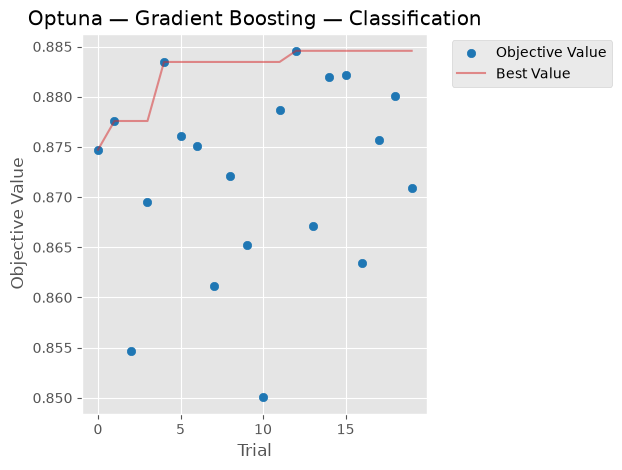

ROC-AUC     Rappel refus  \
Modèle            Étape                                                  
Random Forest     Avant optimisation  0.868 +/- 0.018  0.858 +/- 0.048   
                  Après optimisation  0.878 +/- 0.017  0.868 +/- 0.037   
Gradient Boosting Avant optimisation  0.872 +/- 0.013  0.865 +/- 0.043   
                  Après optimisation  0.885 +/- 0.016  0.870 +/- 0.036   

                                             F1 refus  
Modèle            Étape                                
Random Forest     Avant optimisation  0.835 +/- 0.017  
                  Après optimisation  0.841 +/- 0.017  
Gradient Boosting Avant optimisation  0.845 +/- 0.022  
                  Après optimisation  0.845 +/- 0.015

In [100]:
plot_optimization_history(etude_gb_classification)
plt.title("Optuna — Gradient Boosting — Classification")
plt.tight_layout()
plt.show()

comparaison_classification_optuna = pd.concat({
    "Random Forest": comparaison_rf_classification_optuna,
    "Gradient Boosting": comparaison_gb_classification_optuna,
}, names=["Modèle", "Étape"])

display(comparaison_classification_optuna)